# Projekt zaliczeniowy
#### Temat: Food Delivery Time Prediction 

Zadania do wykonania:
- Analiza eksploracyjna
- Wizualizacje
- Uczenie maszynowe (regresja) 

Opis danych:
- Order_ID: ID dostawy - atrybut ilościowy 
- Distance_km: dystans dostawy w km - atrybut ilościowy 
- Weather: pogoda w trakcie dostawy - atrybut kategoryczny 
- Traffic_Level: poziom zakorkowania - atrybut kategoryczny 
- Time_of_Day: pora dnia - atrybut kategoryczny 
- Vehicle_Type: typ pojazdu - atrybut kategoryczny 
- Preparation_Time_min: minimalny czas przygotowania - atrybut ilościowy 
- Courier_Experience_yrs: doświadczenie kuriera w latach - atrybut ilościowy 
- Delivery_Time_min: całkowity czas dostawy - atrybut ilościowy decyzyjny

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv('Food_Delivery_Times.csv')
df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


Plik 'Food_Delivery_Times.csv' składa się z 1000 wierszy opisujących konkretne dostawy i 9 kolumn przedstawiających atrybuty.

In [3]:
df = df.drop(columns='Order_ID').dropna()
df

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...
995,8.50,Clear,High,Evening,Car,13,3.0,54
996,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


W przypadku braku jakiegokolwiek wartości atrybutu zostaje usunięty cały wiersz. Wykryto 117 braków, a więc analizie poddane będą 883 obiekty. Brak różnic w liczebności pomiędzy kolumnami wskazuje, że dalsza analiza statystyczna oraz modelowanie mogą być prowadzone bez ryzyka zaburzeń wynikających z nierównych prób.

Warto zaznaczyć, że dla zwiększenia czytelności dalszej analizy kolumna 'Order_ID' zostaje usunięta.

In [4]:
df.describe()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,883.000000,883.000000,883.000000,883.000000
mean,10.051586,17.019253,4.639864,56.425821
std,5.688582,7.260201,2.922172,21.568482
min,0.590000,5.000000,0.000000,8.000000
25%,5.130000,11.000000,2.000000,41.000000
50%,10.280000,17.000000,5.000000,55.000000
75%,15.025000,23.000000,7.000000,71.000000
max,19.990000,29.000000,9.000000,141.000000


Zmienność czasu dostawy wskazuje na jego wieloaspektowy charakter problemu. Zaobserwować można zbliżone wartości średniej i mediany, co sugerować może brak silnej skośności danych.

Distance_km: Odległość dostawy jest zmienną o dużej zmienności i istotnym wpływie na czas dostawy. Odchylenie standardowe rónwe 5.69km wskazuje na duże zróżnicowanie tras dostaw, a zakres międzykwartylowy wynoszący 9.9km pokazuje, że połowa dostaw odbywa się na trasie od 5km do 15km.

Preparation_Time_min: Czas przygotowania jest zmienną mającą znaczny wpływ na całkowity czas dostawy. Odchylenie standardowe o wartości 7.26min wskazuje na umiarkowaną zmienność danych. Zauważyć można występowanie outlinerów z uwagi na dużą rozpiętość czasów przygotowania (5-29min). Połowa zamówień została zrealizowana w przedziale 11-23min.

Courier_Experience_yrs: Średnie doświadczenie kuriera (ok 4.6roku) jest mniejsze od mediany (5lat) co wskazuje na lewostronną skośność wykresu tzn niedoświadczeni kurierzy przeważają nad bardziej doświadczonymi. Rozpiętość danych od 0 do 9 lat wskazuje na występowanie zarówno kurierów początkujących jak i dużym doświadczeniem. Połowa dostawców posiada doświadczenie w przedziale 2-7lat.

Delivery_Time_min: Na czas dostawy ma wpływ wiele czynników, co wpływa na jego dużą zmienność. Odchylenie standardowe równe 21.57min wskazuje na duże zróżnicowanie czasów dostaw co widoczne jest w dużym rozstępie danych (od 8 do 141min). Połowa dostaw realizowana w czasie ok 30min.

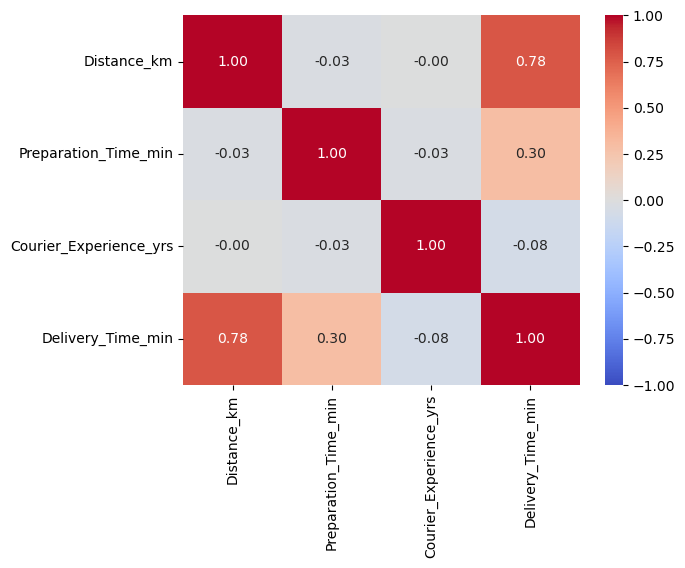

In [5]:
macierz = df.corr(numeric_only=True)
sns.heatmap(macierz, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.show()

Najwyższą korelacją (0.78) z czasem dostawy charakteryzuje się długość trasy. Wynika z tego, że atrybut ten ma największy wpływ na czas realizacji usługi. Średnia korelacja (0.30) dotyczy minimalnego czasu przygotowania, a więc wskazuje to na występowanie powiązania ale na zależność tę wpływają też pozostałe atrybuty. Doświadczenie kuriera nie wpływa znacząco na czas dostawy (korelacja -0.08 oznacza że wzrost doświadczenia kuriera minimalnie może skrócić czas dostawy). W pozostałych przypadkach dane atrybuty są zmiennymi niezależnymi, ponieważ korelacja jest bliska 0 (na doświadczenie kuriera nie wpływa czas przygotowania ani dystans, a na czas przygotowania nie wpływa dystans).

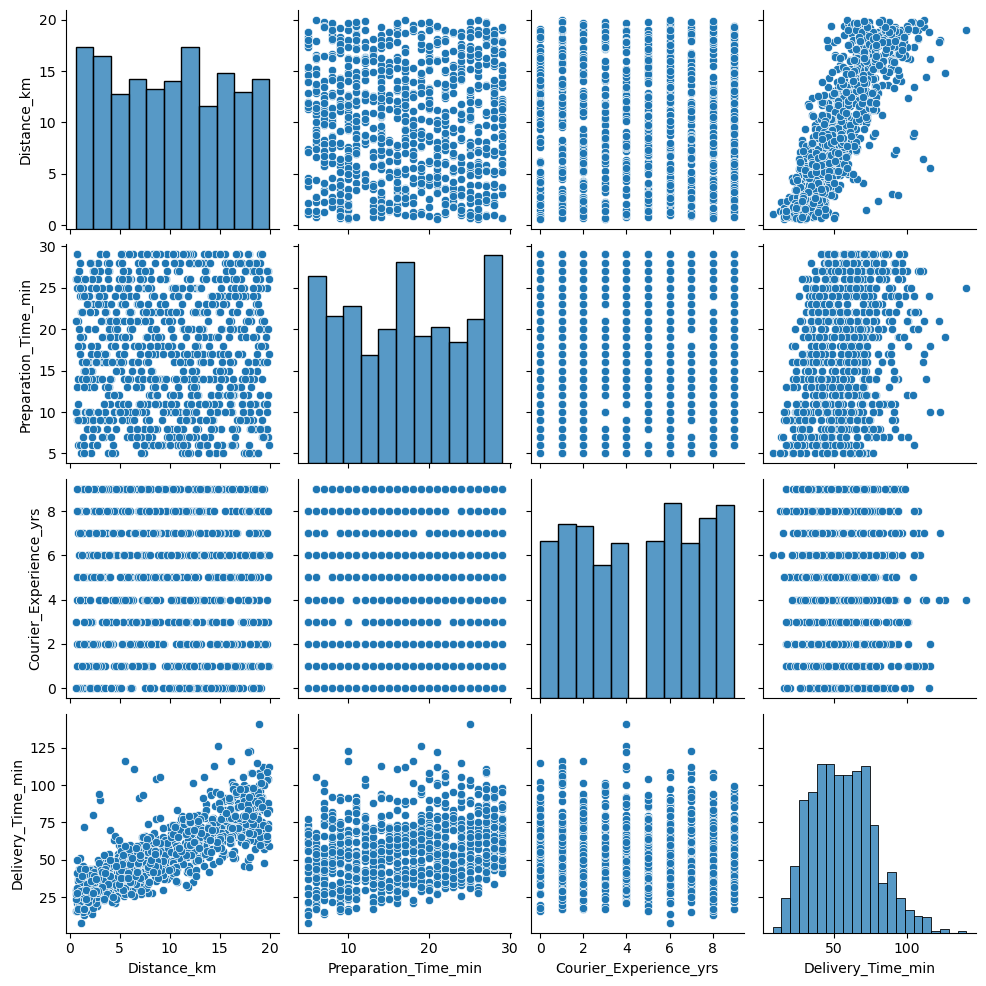

In [6]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist() #atrybuty ilościowe
sns.pairplot(df[num_cols], diag_kind="hist")
plt.show()

Na przekątnej widoczne są histogramy obrazujące pojedynczą zmienną, a poza nią - wykresy punktowe pokazujące zależności parami. 

Histogramy dla Distance_km, Preparation_Time_min oraz Courier_Experience_yrs mają wartości dość równomiernie rozmieszczone. Rozkład dla Delivery_Time_min zbliżony jest do dzwonowego z wydłużonym prawym ogonem, co wynika z dominacji dostaw w czasie 40-70min przy występowaniu również tych powyżej 100min.

W przypadku wykresu Distance_km a Delivery_Time_min widoczna jest wyraźna dodatnia liniowa zależność tzn ze wzrostem odległości wzrasta czas dostawy. Dystans odgrywa kluczową rolę w stosunku do czasu dostawy.

Podobna sytuacja występuje między Preparation_Time_min a Delivery_Time_min - umiarkowana dodatnia zależność. Dla dłuższego czasu przygotowania obserwuje się dłuższy czas dostawy, lecz pomimo wpływu nie jest to czynnik ściśle determinujący.

W pozostałych przypadkach na wykresach nie zaobserwowano wyraźnej zależności między zmiennymi. Warto zwrócić uwagę na wygląd wykresów obrazujących doświadczenie kuriera, ponieważ z faktu że Courier_Experience_yrs jest zmienną dyskretną wynika że punkty "układają się" w pionowe/poziome linie.

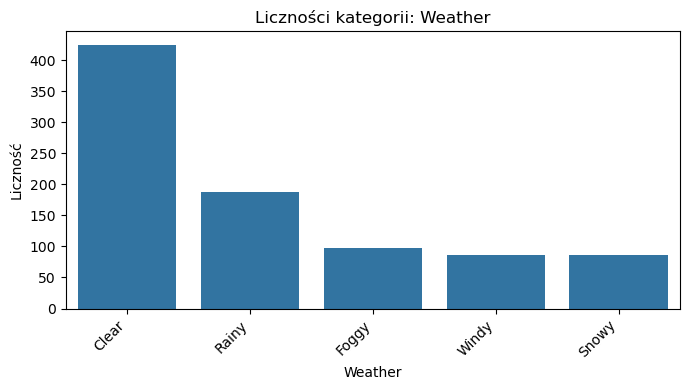

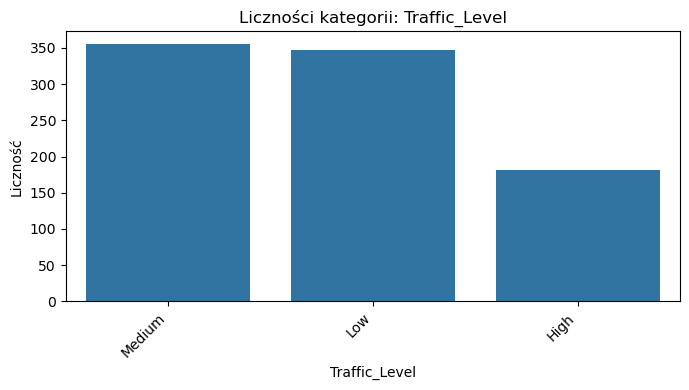

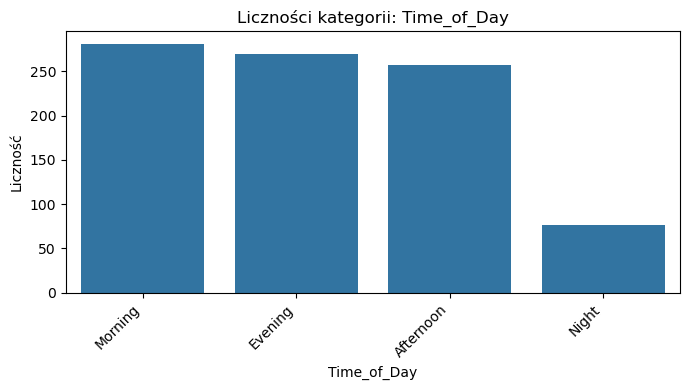

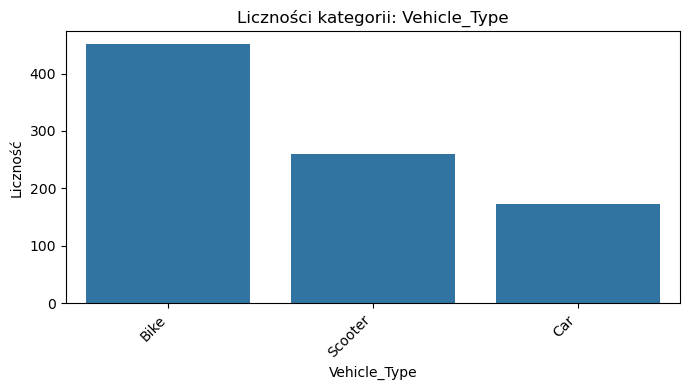

In [7]:
cat_cols = df.select_dtypes(include=["category", "object"]).columns.tolist() #atrybuty kategoryczne
#cat_cols
for col in cat_cols:
    plt.figure(figsize=(7, 4))
    top_counts = df[col].value_counts()
    sns.countplot(x=df[col], order=top_counts.index)
    plt.title(f"Liczności kategorii: {col}")
    plt.xlabel(col)
    plt.ylabel("Liczność")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Wykresy przedstawiające liczności poszczególnych atrybutów kategorycznych wskazują na nierównomierny ich rozkład. Niektóre typy danych występują zdecydowanie częściej co w dalszym rozważaniu wpływać na ograniczenia zdolności modeli regresyjnyvh do uczenia wzorców dla rzadkich kategorii. 

Dla atrybutu Weather: najczęściej Clear, najrzadziej Snowy/Windy.

Dla atrybutu Traffic_Level: najczęściej Medium, najrzadziej High.

Dla atrybutu Time_of_Day: najczęściej Morning, najrzadziej NIght.

Dla atrybutu Vehicle_Type: najczęściej Bike, najrzadziej Car.

Aby przygotować zbiór do uczenia nadzorowanego, najpierw odszukujemy kategorie pojawiajace się rzadko, po czym przygotowujemy zbiory treningowy i testowy:

In [8]:
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
threshold = 0.05

# sprawdzanie rzadkich atrybutów (mniej niż 5%)
for col in cat_cols:
    counts = df[col].value_counts(normalize=True)
    rare = counts[counts < threshold]
    if not rare.empty:
        print(f"Rzadkie wartości w {col}: {rare.index.tolist()} ({rare.values})")
    else:
        print(f"Brak rzadkich wartości w {col}")

Brak rzadkich wartości w Weather
Brak rzadkich wartości w Traffic_Level
Brak rzadkich wartości w Time_of_Day
Brak rzadkich wartości w Vehicle_Type


In [9]:
# podział na zbiór treningowy i testowy
df_ml = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_ml.drop('Delivery_Time_min', axis=1)
y = df_ml['Delivery_Time_min']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Przygotowujemy trzy modele: regresję liniową, drzewo decyzyjne, random forest. Dla każdego z modeli obliczamy MAE (Mean Absolute Error - średni błąd bezwzględny) oraz RMSE (Root Mean Squared Error - pierwiastek błędu średniokwadratowego). 

              Model       MAE       RMSE
0  Regresja Liniowa  5.319617   8.273317
1  Drzewo Decyzyjne  8.311563  11.089678
2     Random Forest  6.984520   9.930387


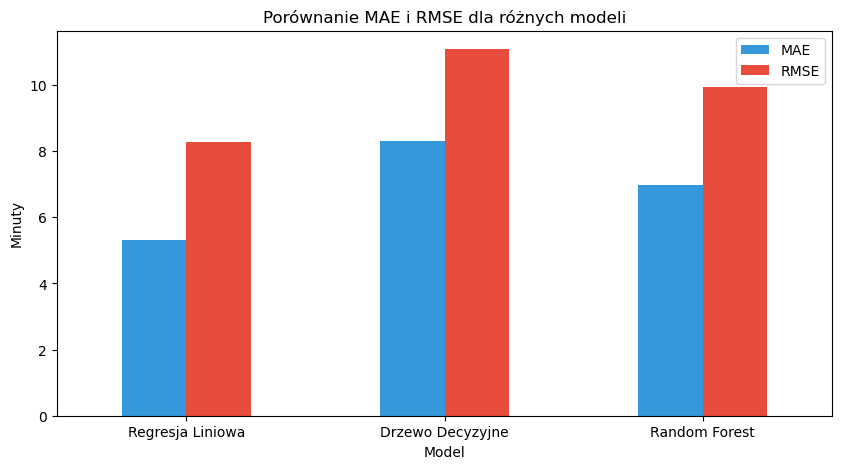

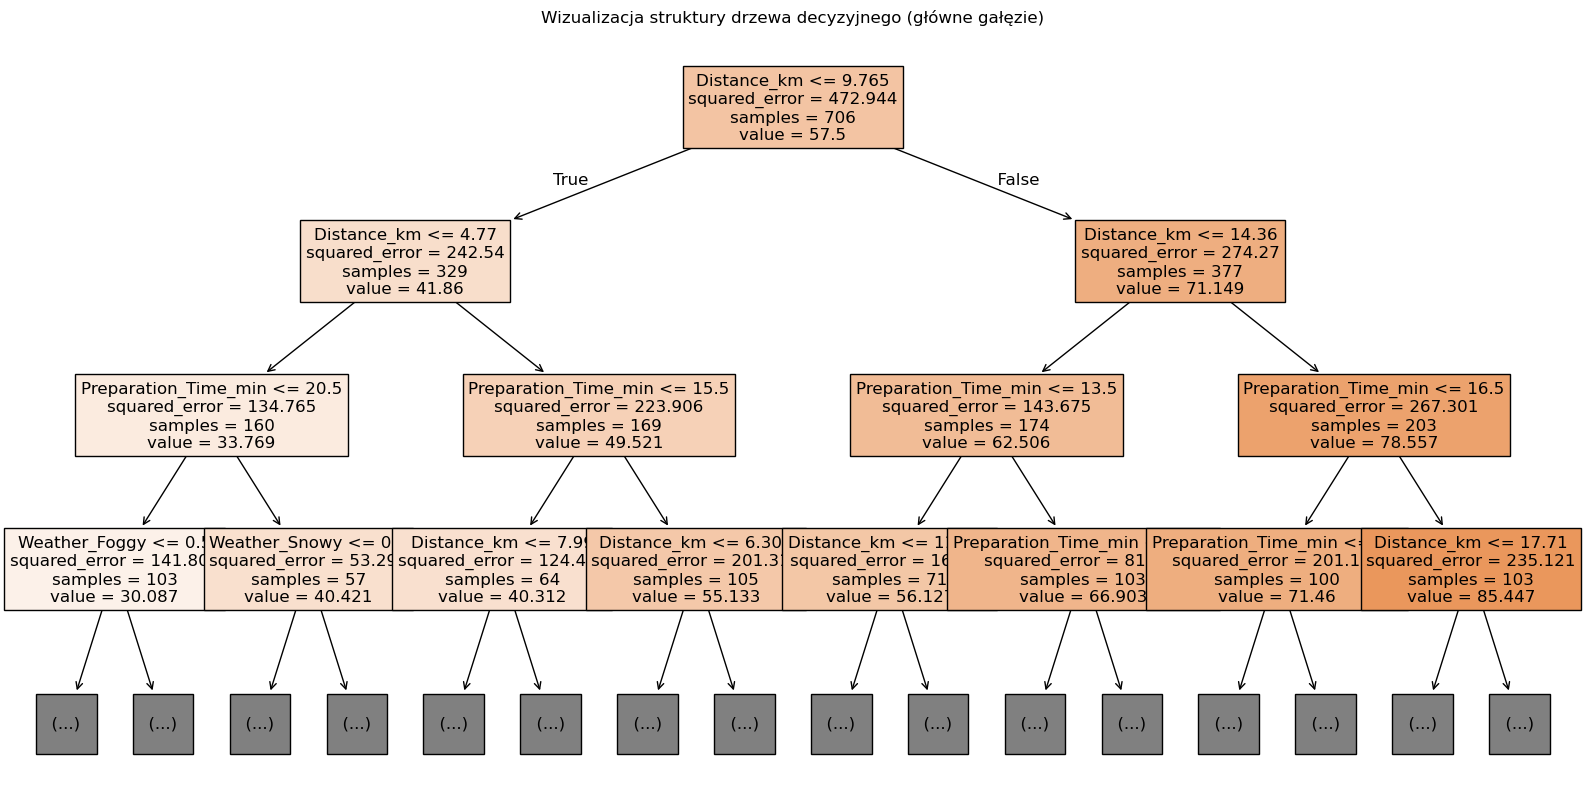

In [17]:
models = {
    "Regresja Liniowa": LinearRegression(),
    "Drzewo Decyzyjne": DecisionTreeRegressor(random_state=42, max_depth=5),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=100)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    results.append({"Model": name, "MAE": mae, "RMSE": rmse})

results_df = pd.DataFrame(results)
print(results_df)

# wyniki obliczeń przedstawiamy na wykresie
results_df.set_index('Model').plot(kind='bar', figsize=(10, 5), color=['#3498db', '#e74c3c'])
plt.title("Porównanie MAE i RMSE dla różnych modeli")
plt.ylabel("Minuty")
plt.xticks(rotation=0)
plt.show()

# wizualizacja drzewa decyzyjnego
plt.figure(figsize=(20, 10))
plot_tree(models["Drzewo Decyzyjne"], 
          feature_names=X.columns.tolist(), 
          filled=True, 
          max_depth=3,
          fontsize=12)
plt.title("Wizualizacja struktury drzewa decyzyjnego (główne gałęzie)")
plt.show()

Na wykresie widać, że błąd RMSE jest zawsze większy, niż błąd MAE - oznacza to, że w zbiorze danych pojawiają się dosyć często specyficzne przypadki, w których model bardziej drastycznie się myli.

Przygotowujemy również modele regresyjne dla poszczególnych kategorii - w ten sposób określamy, jak np. rodzaj pojazdu wpływa na przewidywanie czasu dostawy.

In [18]:
analysis_categories = ['Vehicle_Type', 'Weather', 'Traffic_Level', 'Time_of_Day']

for category in analysis_categories:
    print(f"\n>>> Analiza dla atrybutu: {category}")
    unique_values = df[category].unique()
    
    for val in unique_values:
        subset = df[df[category] == val].copy()
        
        if len(subset) < 30:
            print(f"  - {val:12}: Zbyt mało danych ({len(subset)} wierszy)")
            continue
            
        subset_ml = pd.get_dummies(subset.drop(columns=[category]), drop_first=True)
        
        X_sub = subset_ml.drop('Delivery_Time_min', axis=1)
        y_sub = subset_ml['Delivery_Time_min']
        
        X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_sub, y_sub, test_size=0.2, random_state=42)
        
        rf_sub = RandomForestRegressor(random_state=42, n_estimators=50)
        rf_sub.fit(X_train_s, y_train_s)
        
        preds_sub = rf_sub.predict(X_test_s)
        mae_sub = mean_absolute_error(y_test_s, preds_sub)
        
        print(f"  - {val:12}: MAE = {mae_sub:.2f} min (na podstawie {len(subset)} zamówień)")


>>> Analiza dla atrybutu: Vehicle_Type
  - Scooter     : MAE = 7.82 min (na podstawie 260 zamówień)
  - Bike        : MAE = 9.70 min (na podstawie 451 zamówień)
  - Car         : MAE = 10.77 min (na podstawie 172 zamówień)

>>> Analiza dla atrybutu: Weather
  - Windy       : MAE = 7.73 min (na podstawie 86 zamówień)
  - Clear       : MAE = 7.05 min (na podstawie 425 zamówień)
  - Foggy       : MAE = 9.07 min (na podstawie 98 zamówień)
  - Rainy       : MAE = 10.06 min (na podstawie 188 zamówień)
  - Snowy       : MAE = 5.43 min (na podstawie 86 zamówień)

>>> Analiza dla atrybutu: Traffic_Level
  - Low         : MAE = 8.65 min (na podstawie 347 zamówień)
  - Medium      : MAE = 8.86 min (na podstawie 355 zamówień)
  - High        : MAE = 9.64 min (na podstawie 181 zamówień)

>>> Analiza dla atrybutu: Time_of_Day
  - Afternoon   : MAE = 6.63 min (na podstawie 257 zamówień)
  - Evening     : MAE = 8.41 min (na podstawie 269 zamówień)
  - Night       : MAE = 6.30 min (na podstawie 76 zam

Na podstawie tej analizy można wyciągnąć kilka wniosków:
- Dla dostawy samochodem trudniej jest przewidzieć dokładny czas dostawy, niż dla dostawy rowerem lub hulajnogą; prawdopodobnie jest to związane z czynnikiem zagęszczenia ruchu ulicznego, który jest znacznie bardziej istotny dla dostawy samochodem, niż dla pozostałych środków transportu;
- Widać wyraźnie wysoki błąd dla pogody deszczowej. Prawdopodobnie takie warunki pogodowe wprowadzają losowość (pogorszona widoczność, utrudnienia w ruchu) która utrudnia dokładne przewidywanie czasu. Co ciekawe, widać też bardzo niską wartość błędu MAE dla kategorii 'Snowy', mimo że intuicja podpowiada, że tak trudne warunki pogodowe jeszcze bardziej utrudniłyby przewidywanie czasu.  Może to świadczyć o mniejszej zmienności czasu dostaw w ekstremalnych warunkach (bardziej przewidywalne tempo jazdy) lub wynikać z mniejszej reprezentacji tej kategorii w zbiorze danych, co upraszcza zadanie regresji dla modelu w tym konkretnym podzbiorze.
- Czas dostawy jest nieco trudniejszy do przewidzenia przy wysokim poziomie ruchu, niż przy niskim, jednak ta różnica nie jest duża. Prawdopodobnie wynika to z faktu, że ten konkretny model nie bierze pod uwagę środka transportu, a dla dwóch z trzech analizowanych środków transportu (roweru i hulajnogi) poziom ruchu nie jest bardzo istotny.
- przewidywanie czasu dostawy jest łatwiejsze po południu i w nocy, niż rano i wieczorem. Może mieć to związek z zagęszczeniem ruchu ulicznego w tym czasie (rano i wieczorem ruch jest większy, niż po południu i w nocy) i mniejszą liczbą zdarzeń losowych na drogach o tych porach dnia.